# RoadSight · Phase 2 starter
Jahnavi Reddy Poddutoori · CS 5330

Open in Google Colab and choose **Runtime → Run all**. Three Phase 1 JPEGs and their candidate annotation records are bundled below. Each JPEG matched a unique record by byte length among 10,000 records and by image dimensions. Inspect the traffic boxes as a visual check. The boxes come from dataset annotations. This notebook tests the loading and lighting-correction stages before detector training.

In [1]:
#@title Load bundled Phase 1 examples
examples = [{'name': 'b1c66a42-6f7d68ca', 'light': 'daytime', 'jpeg': '...', 'objects': [('traffic sign', [0.7817958921875, 0.39165613194444443, 0.031193851562500007, 0.06238770138888891]), ('traffic sign', [0.16766694921875, 0.23915285833333333, 0.04679077656250001, 0.07971761805555558]), ('traffic sign', [0.6229022132812501, 0.4349809236111111, 0.025345003124999987, 0.039858809722222256]), ('traffic sign', [0.50982450234375, 0.4211169888888889, 0.025345003906249986, 0.017329916666666712]), ('traffic light', [0.55271604921875, 0.43324793055555555, 0.006823654687500014, 0.02252889305555554]), ('traffic light', [0.4893535390625, 0.4107190388888889, 0.007798462500000003, 0.02946085972222221]), ('traffic light', [0.24760119296875, 0.4020540805555556, 0.009748078124999981, 0.02426188472222219]), ('traffic sign', [0.21153330234375, 0.40032108888888884, 0.030219043749999973, 0.01906290833333336]), ('traffic sign', [0.17254098906249998, 0.41765100555555557, 0.008773270312500015, 0.015596927777777757]), ('car', [0.16084329453125, 0.46964075833333335, 0.059463278125000005, 0.06931966805555557]), ('car', [0.0370426984375, 0.47830571666666666, 0.0643373171875, 0.07798462916666667]), ('car', [0.193011953125, 0.47830571666666666, 0.07798462812500002, 0.07105266111111111]), ('car', [0.0, 0.46790776666666667, 0.0409419296875, 0.09184856111111112]), ('rider', [0.5078748875, 0.49216965, 0.010722886718750057, 0.03812581805555561]), ('motorcycle', [0.50690007890625, 0.5094995694444445, 0.011697695312500044, 0.02946085694444444]), ('traffic light', [0.5566152796875, 0.46790776666666667, 0.010722886718749968, 0.02252889305555554]), ('car', [0.5341946992187501, 0.4956356319444445, 0.02924423593749994, 0.05025675972222222]), ('car', [0.551741240625, 0.5060335819444445, 0.021445773437500027, 0.03639282777777776]), ('car', [0.56831297421875, 0.5077665763888889, 0.026319811718749975, 0.048523769444444455]), ('car', [0.5848847078125, 0.5025676, 0.04679077656250001, 0.06585368611111109]), ('car', [0.61510375078125, 0.497368625, 0.09260674531249995, 0.09358155416666665]), ('car', [0.68723953125, 0.5216305097222222, 0.06238770234375002, 0.10571249444444446]), ('car', [0.7299653148116186, 0.46516093399921654, 0.2154325335937501, 0.20622601666666673]), ('car', [0.94068957109375, 0.5770862458333333, 0.05848847109374997, 0.15943523888888894]), ('traffic light', [0.47083218984375, 0.4731067416666667, 0.005848846875000024, 0.017329918055555518]), ('traffic light', [0.46205891875000005, 0.4557768236111111, 0.004874039062499946, 0.019062909722222247]), ('traffic light', [0.4133185265625, 0.46097579861111115, 0.005848846874999936, 0.013863934722222224]), ('car', [0.43086506796875, 0.49390264166666664, 0.010722885937499971, 0.017329918055555598]), ('car', [0.44841161015625, 0.4887036666666667, 0.009748078124999981, 0.02426188472222219]), ('car', [0.45426045703125, 0.4956356319444445, 0.012672501562499949, 0.02946085972222221]), ('car', [0.46595814999999996, 0.4887036666666667, 0.031193851562500007, 0.046790776388888844]), ('car', [0.40454525625000004, 0.49390264166666664, 0.013647309374999939, 0.017329918055555598]), ('car', [0.39187275390625, 0.4956356319444445, 0.012672502343750036, 0.019062909722222167]), ('car', [0.3538552484375, 0.49043665694444444, 0.02047096406250004, 0.02772786944444445])]}, {'name': 'b1c9c847-3bda4659', 'light': 'daytime', 'jpeg': '...', 'objects': [('traffic sign', [0.4871854921875, 0.4280962541666667, 0.009185988281249991, 0.009526212499999945]), ('car', [0.25447376718750003, 0.47631056805555555, 0.03980595390624999, 0.057157265277777786]), ('car', [0.19170284140625, 0.4627016916666667, 0.07119141640625001, 0.07893146527777775]), ('car', [0.12740091874999998, 0.4749496805555556, 0.08190840390625001, 0.08709678611111107]), ('car', [0.0240585421875, 0.4654234666666667, 0.11405936562499999, 0.11295364305555554]), ('car', [0.48981006328125, 0.4640625819444445, 0.01377898203125003, 0.019052420833333313]), ('car', [0.5349745109375, 0.4558972569444444, 0.022199471874999953, 0.03538306944444448]), ('car', [0.55115935703125, 0.46250726666666664, 0.0068894914062499705, 0.02857863472222222]), ('car', [0.554986853125, 0.4557028291666667, 0.012247985156250075, 0.04218750555555554]), ('car', [0.55957984765625, 0.45298105694444446, 0.019902977343750017, 0.05987903750000001]), ('car', [0.5682966620175169, 0.442928046691081, 0.054579674203099685, 0.09798388333333329]), ('car', [0.58637231484375, 0.4611463791666667, 0.034447459375000024, 0.08981856111111107]), ('car', [0.5955583046874999, 0.4189588763888889, 0.13396234218750003, 0.18916332916666662]), ('car', [0.6466280234374999, 0.44209395833333337, 0.2931861515625001, 0.2803427777777777]), ('car', [0.30116921328125, 0.46814524444444444, 0.04899194140624998, 0.05449452561110451]), ('car', [0.4692509546875, 0.4654234666666667, 0.022199474218750036, 0.02313508194444446]), ('car', [0.5236013914062501, 0.4640625819444445, 0.014544482812500004, 0.01633064444444443]), ('car', [0.35442609062499997, 0.37349852230391445, 0.10946636874999997, 0.19535237908497444]), ('car', [0.0, 0.43528951944444444, 0.03247903125, 0.1646673611111111])]}, {'name': 'b1c81faa-3df17267', 'light': 'night', 'jpeg': '...', 'objects': [('car', [0.6402062914062501, 0.3890034791666667, 0.054510317968749965, 0.04536083333333328]), ('car', [0.80257745234375, 0.40343647222222223, 0.01971649687500001, 0.022680415277777793]), ('traffic sign', [0.8292527140624999, 0.32508594305555555, 0.05682990625000013, 0.04329897638888889]), ('traffic light', [0.7851805421875, 0.3663230791666666, 0.019716496874999923, 0.022680418055555564])]}]

In [2]:
import base64
import cv2
import numpy as np
import matplotlib.pyplot as plt

targets = {"rider", "bicycle", "motorcycle"}
gamma_table = np.rint(255 * (np.arange(256) / 255.0) ** 0.65).astype(np.uint8)

def prepare(frame):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    median = float(np.median(gray))
    dark = float((gray < 40).mean())
    correct = median < 45 and dark > 0.50
    selected = cv2.LUT(frame, gamma_table) if correct else frame.copy()
    return selected, median, dark, correct

def annotate(frame, objects):
    canvas = frame.copy()
    h, w = canvas.shape[:2]
    for label, (x, y, bw, bh) in objects:
        start = (round(x*w), round(y*h))
        end = (round((x+bw)*w), round((y+bh)*h))
        color = (50, 215, 50) if label in targets else (210, 180, 40)
        cv2.rectangle(canvas, start, end, color, 2)
        if label in targets:
            cv2.putText(canvas, label, start, cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return canvas

## Compare the original, the selected input, and the annotation overlay
The preliminary rule brightens an image if its median grayscale intensity is below 45 and more than half its pixels are below 40 on the 0–255 scale. Green boxes mark project classes. Other road objects provide extra alignment checks.

b1c66a42-6f7d68ca | daytime | median 69 | dark 21.0% | corrected False | target labels ['rider', 'motorcycle']
b1c9c847-3bda4659 | daytime | median 78 | dark 17.5% | corrected False | target labels []
b1c81faa-3df17267 | night | median 10 | dark 93.2% | corrected True | target labels []


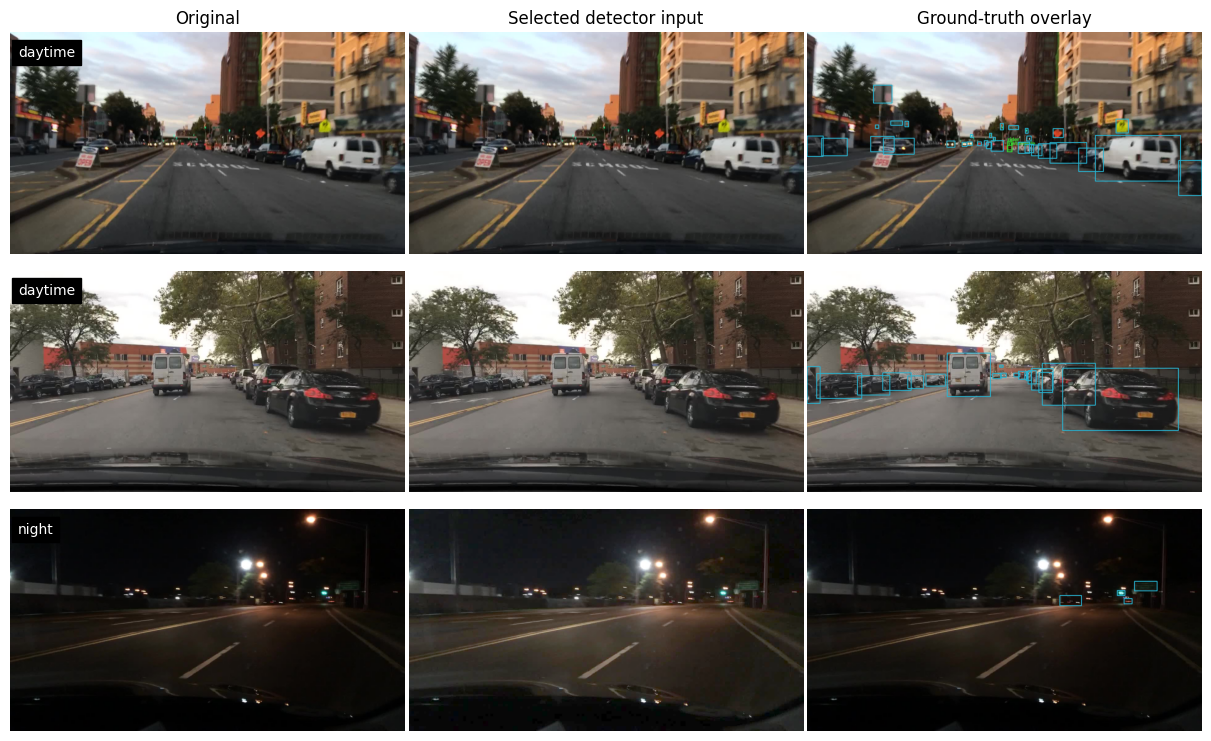

In [3]:
fig, grid = plt.subplots(len(examples), 3, figsize=(12, 7.5), squeeze=False)
for row, sample in enumerate(examples):
    buffer = np.frombuffer(base64.b64decode(sample["jpeg"]), dtype=np.uint8)
    original = cv2.imdecode(buffer, cv2.IMREAD_COLOR)
    assert original is not None and original.shape[:2] == (720, 1280)
    selected, median, dark, corrected = prepare(original)
    labels = [label for label, _ in sample["objects"] if label in targets]
    print(f'{sample["name"]} | {sample["light"]} | median {median:.0f} | dark {dark:.1%} | corrected {corrected} | target labels {labels}')
    axes = grid[row]
    for ax, frame, title in zip(axes, [original, selected, annotate(original, sample["objects"])], ["Original", "Selected detector input", "Ground-truth overlay"]):
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(title if row == 0 else "")
        ax.axis("off")
    axes[0].text(0.02, 0.94, sample["light"], color="white", backgroundcolor="black", transform=axes[0].transAxes, va="top")
fig.tight_layout(pad=0.3)
plt.show()

# Step 2 · Run the first detector baseline
Run the setup and prediction cells below. On first use, Colab downloads Ultralytics and YOLOv8n weights. This pretrained pilot covers bicycle and motorcycle. Rider stays in the ground-truth display for the later three-class model. Each row compares the same scene before and after selective correction. An empty prediction panel means no target passed the confidence threshold.

In [4]:
%pip -q install ultralytics==8.3.253

In [5]:
from ultralytics import YOLO
import csv
from pathlib import Path

detector = YOLO("yolov8n.pt")
pilot_classes = {"bicycle", "motorcycle"}
class_ids = [i for i, name in detector.names.items() if name in pilot_classes]
assert {detector.names[i] for i in class_ids} == pilot_classes

def box_iou(a, b):
    x1, y1 = np.maximum(a[:2], b[:2])
    x2, y2 = np.minimum(a[2:], b[2:])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = np.prod(np.maximum(0, a[2:] - a[:2]))
    area_b = np.prod(np.maximum(0, b[2:] - b[:2]))
    return intersection / max(area_a + area_b - intersection, 1e-9)

def score_scene(result, sample):
    h, w = result.orig_shape
    truth = []
    for label, (x, y, bw, bh) in sample["objects"]:
        if label in pilot_classes:
            truth.append((label, np.array([x*w, y*h, (x+bw)*w, (y+bh)*h])))
    remaining = set(range(len(truth)))
    boxes = result.boxes
    for k in boxes.conf.argsort(descending=True).tolist():
        label = detector.names[int(boxes.cls[k].item())]
        coords = boxes.xyxy[k].cpu().numpy()
        matches = [(box_iou(coords, truth[j][1]), j) for j in remaining if truth[j][0] == label]
        overlap, j = max(matches, default=(0, None))
        if overlap >= 0.5:
            remaining.remove(j)
    hits = len(truth) - len(remaining)
    return hits, len(boxes) - hits, len(remaining)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


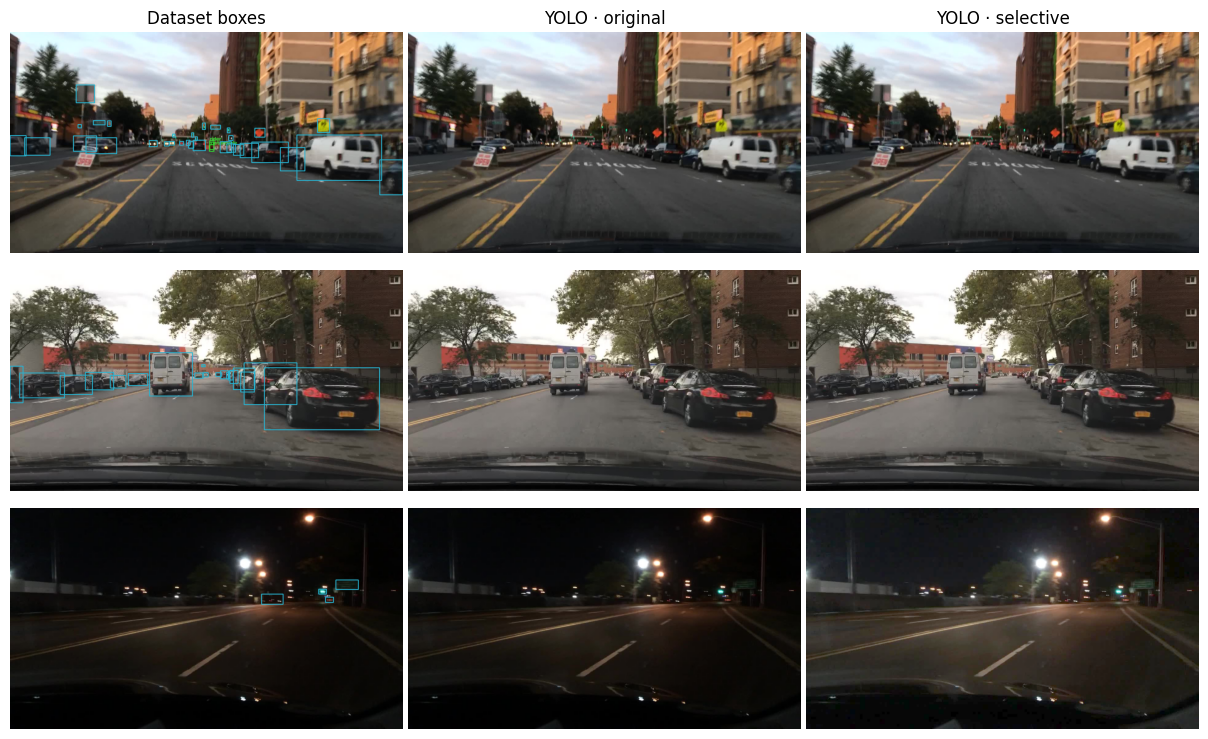

,image,lighting,mode,corrected,TP,FP,FN
0,b1c66a42-6f7d68ca,daytime,Original,False,0,0,1
1,b1c66a42-6f7d68ca,daytime,Selective,False,0,0,1
2,b1c9c847-3bda4659,daytime,Original,False,0,0,0
3,b1c9c847-3bda4659,daytime,Selective,False,0,0,0
4,b1c81faa-3df17267,night,Original,False,0,0,0
5,b1c81faa-3df17267,night,Selective,True,0,0,0


In [6]:
records = []
fig, axes = plt.subplots(len(examples), 3, figsize=(12, 7.5), squeeze=False)
for row, sample in enumerate(examples):
    raw = np.frombuffer(base64.b64decode(sample["jpeg"]), dtype=np.uint8)
    original = cv2.imdecode(raw, cv2.IMREAD_COLOR)
    selected, _, _, corrected = prepare(original)
    panels = [annotate(original, sample["objects"])]
    for mode, frame in [("Original", original), ("Selective", selected)]:
        result = detector.predict(frame, imgsz=640, conf=0.25, classes=class_ids, verbose=False)[0]
        hits, false_alarms, misses = score_scene(result, sample)
        records.append(dict(image=sample["name"], lighting=sample["light"], mode=mode,
                            corrected=bool(corrected and mode=="Selective"),
                            TP=hits, FP=false_alarms, FN=misses))
        panels.append(result.plot())
    for col, panel in enumerate(panels):
        axes[row, col].imshow(cv2.cvtColor(panel, cv2.COLOR_BGR2RGB))
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(["Dataset boxes", "YOLO · original", "YOLO · selective"][col])
fig.tight_layout(pad=0.4)
fig.savefig("roadsight_baseline.jpg", dpi=160, bbox_inches="tight")
plt.show()

with Path("roadsight_baseline.csv").open("w", newline="") as output:
    writer = csv.DictWriter(output, fieldnames=records[0].keys())
    writer.writeheader()
    writer.writerows(records)
import pandas as pd
display(pd.DataFrame(records))

TP = correct detection, FP = false alarm, FN = missed labeled object. Matching uses the same class and IoU ≥ 0.50. These three scenes check that inference and scoring run. Only one scene has a labeled bicycle or motorcycle, and the nighttime scene has neither. The next evaluation needs positive nighttime and dawn/dusk examples before interpreting recall by lighting.

RoadSight brightened this image: True | Dark pixels: 77.5%
YOLO on original: motorcycle FOUND | false alarms: 0
YOLO after RoadSight: motorcycle FOUND | false alarms: 0


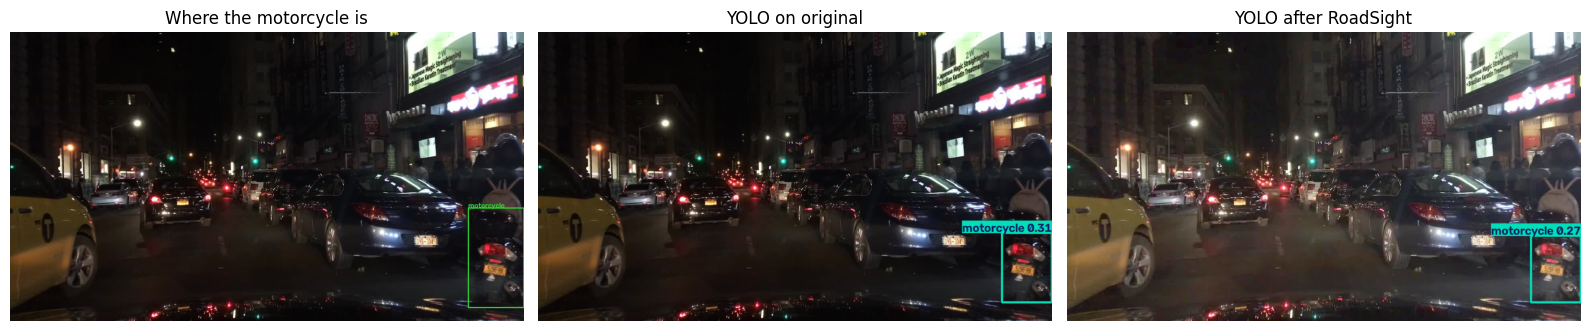

In [7]:
import requests

# Load the nighttime photo that matches the annotation in samples.json
url = "https://huggingface.co/datasets/dgural/bdd100k/resolve/main/data/b29f09ea-911177ce.jpg"
response = requests.get(url, timeout=60)
response.raise_for_status()
night = cv2.imdecode(np.frombuffer(response.content, np.uint8), cv2.IMREAD_COLOR)
assert night is not None, "The downloaded file could not be opened as an image."

sample = {"objects": [("motorcycle", [0.89134442, 0.60805546, 0.10789690, 0.34478445])]}
selected, median, dark, corrected = prepare(night)

print(f"RoadSight brightened this image: {corrected} | Dark pixels: {dark:.1%}")
panels = [("Where the motorcycle is", annotate(night, sample["objects"]))]

for title, frame in [("YOLO on original", night), ("YOLO after RoadSight", selected)]:
    result = detector.predict(frame, imgsz=640, conf=0.25, classes=class_ids, verbose=False)[0]
    hits, false_alarms, misses = score_scene(result, sample)
    print(f"{title}: motorcycle {'FOUND' if hits else 'MISSED'} | false alarms: {false_alarms}")
    panels.append((title, result.plot()))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (title, frame) in zip(axes, panels):
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

RoadSight applied lighting correction to a nighttime scene with 77.5% dark pixels. YOLO detected the labeled motorcycle in both versions, with confidence decreasing from 0.31 to 0.27 and no false alarms in either version

In [8]:
import requests
import pandas as pd
from pathlib import Path

# Fixed image IDs and ground-truth boxes from your samples.json.
# Box format: left, top, width, height (normalized to image dimensions).
batch = """
daytime b69fc2ae-156d58aa bicycle .879468 .5718688 .1188496 .1570638
daytime bdb658c2-01af4ab1 bicycle .8663428 .4996871 .0685546 .1710936
daytime c6a0e7c1-4171ca59 motorcycle .5042855 .6361605 .0251675 .035625
daytime ba73ab52-4980c05c motorcycle .274015 .3779394 .0115669 .0340358
daytime c4b90e82-0a023704 none
daytime ca2ba838-fdddb1fb none
dawn/dusk c98258a4-b78aa787 bicycle .0101354 .4712524 .0740663 .1178131
dawn/dusk c690ecdd-4d7973ad bicycle .7542095 .5204084 .0585459 .0704082
dawn/dusk c330c787-ac4f1ff5 motorcycle .4517221 .5229594 .0094707 .0290816
dawn/dusk b7446774-2faa796d motorcycle .3593415 .530238 .04206 .0503021
dawn/dusk b5046f1e-b1ef44b9 none
dawn/dusk c96ab7ea-2770185c none
night c1d9b74d-d3c2b059 bicycle .544718 .4481107 .0350677 .0872796
night b5261cec-aac2f91a bicycle .8557848 .4858568 .0705927 .1254981
night c90ff73f-d76cc0c4 motorcycle .8572826 .473774 .0702064 .0713208
night c614250f-612cd1b1 motorcycle .4644394 .3927489 .0652119 .0884746
night c44f673a-b4b48b84 none
night b44a7e5f-1db66cfe none
""".strip().splitlines()

cache = Path("roadsight_pilot_images")
cache.mkdir(exist_ok=True)
base = "https://huggingface.co/datasets/dgural/bdd100k/resolve/main/data"
rows = []

for line in batch:
    lighting, image_id, label, *coords = line.split()
    path = cache / f"{image_id}.jpg"
    frame = cv2.imread(str(path)) if path.exists() else None
    if frame is None:
        response = requests.get(f"{base}/{path.name}", timeout=60)
        response.raise_for_status()
        frame = cv2.imdecode(np.frombuffer(response.content, np.uint8), cv2.IMREAD_COLOR)
        if frame is None:
            raise ValueError(f"Could not open {image_id}")
        path.write_bytes(response.content)

    objects = [] if label == "none" else [(label, list(map(float, coords)))]
    selected, _, _, corrected = prepare(frame)
    row = dict(image=image_id, lighting=lighting, label=label, brightened=int(corrected))

    for mode, image in [("original", frame), ("selective", selected)]:
        prediction = detector.predict(
            image, imgsz=640, conf=0.25, classes=class_ids, verbose=False
        )[0]
        hits, false_alarms, misses = score_scene(prediction, {"objects": objects})
        row[f"{mode}_hits"] = hits
        row[f"{mode}_false_alarms"] = false_alarms
        row[f"{mode}_misses"] = misses

    # Each positive image has exactly one labeled target.
    row["recovered"] = int(row["selective_hits"] > row["original_hits"])
    row["lost"] = int(row["selective_hits"] < row["original_hits"])
    rows.append(row)

results = pd.DataFrame(rows)
summary = results.groupby("lighting", sort=False).agg(
    images=("image", "count"),
    brightened=("brightened", "sum"),
    original_hits=("original_hits", "sum"),
    selective_hits=("selective_hits", "sum"),
    recovered=("recovered", "sum"),
    lost=("lost", "sum"),
    original_false_alarms=("original_false_alarms", "sum"),
    selective_false_alarms=("selective_false_alarms", "sum"),
)

results.to_csv("roadsight_pilot_per_image.csv", index=False)
summary.to_csv("roadsight_pilot_summary.csv")
display(summary)

,images,brightened,original_hits,selective_hits,recovered,lost,original_false_alarms,selective_false_alarms
lighting,,,,,,,,
daytime,6,0,0,0,0,0,1,1
dawn/dusk,6,3,0,0,0,0,0,0
night,6,5,0,1,1,0,0,0


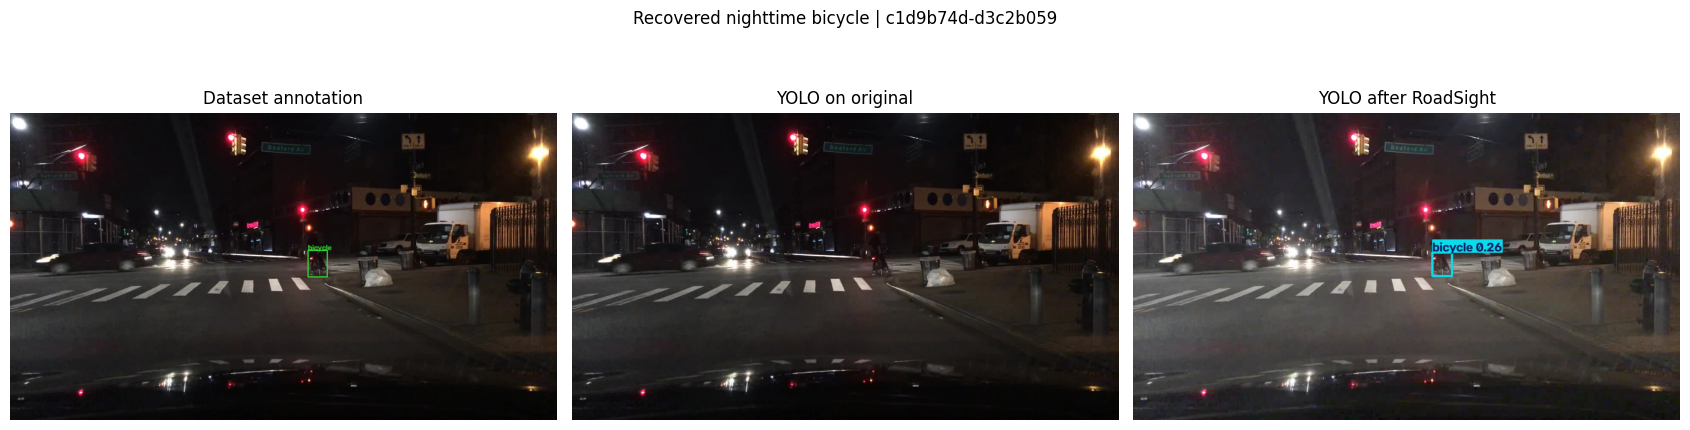

In [9]:
hit = results.loc[results["recovered"] == 1].iloc[0]
image_id = hit["image"]
label = hit["label"]

# Get the labeled box for this exact image from the pilot batch.
entry = next(line.split() for line in batch if line.split()[1] == image_id)
objects = [(label, list(map(float, entry[3:])))]

original = cv2.imread(str(cache / f"{image_id}.jpg"))
selected, _, _, _ = prepare(original)

panels = [("Dataset annotation", annotate(original, objects))]
for title, frame in [("YOLO on original", original), ("YOLO after RoadSight", selected)]:
    prediction = detector.predict(
        frame, imgsz=640, conf=0.25, classes=class_ids, verbose=False
    )[0]
    panels.append((title, prediction.plot()))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (title, panel) in zip(axes, panels):
    ax.imshow(cv2.cvtColor(panel, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(f"Recovered nighttime {label} | {image_id}")
fig.tight_layout()
fig.savefig("roadsight_recovered_night.png", dpi=180, bbox_inches="tight")
plt.show()